# Interactive Apps and Dashboards with Shiny

From a first app to a published dashboard, all in R

## Today’s roadmap

1.  **Getting started with Shiny:** what it is, how an app is built, how
    to run it
2.  **What is a dashboard?** and why some dashboards need a server
3.  **Dashboards with bslib:** modern layouts with very little code
4.  **Demo:** a fuel economy dashboard, then sharing it with the world

**Everything is in the lecture folder:**

    shiny-lecture/
    ├── shiny-lecture.ipynb        <- these notes
    ├── apps/
    │   ├── 01-hello-shiny/        <- first app
    │   ├── 02-mpg-explorer/       <- more widgets, more reactivity
    │   ├── 03-hello-bslib/        <- first dashboard
    │   └── 04-mpg-dashboard/      <- final product
    └── images/

<a href="shiny-example-apps.zip"
download="shiny-example-apps.zip">Download the example apps</a>

Here are nine slides for the front of the lecture. Each cell starts with
a `##` header, so you can split them into separate notebook cells where
you like.

One small terminology point: when you run an app locally, Shiny starts a
real web server, a small program running on your own computer, rather
than a “virtual” one. The slides call it a “local server,” which keeps
the idea you wanted.

```` markdown
# How the Web Works: Clients and Servers

The big picture behind every web app

## Clients and servers

Every time you use the web, two sides are talking:

- **Client:** the program that *asks* for something (usually your web browser)
- **Server:** the program that *answers* (sends back a page, data, or a result)

**Restaurant analogy**

| Restaurant | Web |
|---|---|
| Customer places an order | Browser sends a **request** |
| Kitchen prepares the food | Server does the work |
| Waiter brings the plate | Server sends a **response** |

- You never see the kitchen, only the plate
- Each click, search, or slider move can be a new request

## A server is a program, not just a machine

- "Server" often means a big computer in a data center, but strictly it is **software that listens for requests and answers them**
- Any computer can run a server, **including your laptop**
- One computer can run many servers at once

**Examples**

- Google's servers answer searches
- Canvas's servers send your grades and assignments
- Your laptop running a Shiny app: also a server

## Client-side vs. server-side tools

**Where does the work happen?**

| | Client-side | Server-side |
|---|---|---|
| Runs on | The viewer's browser | A server somewhere else |
| Examples | Plotly charts, Quarto websites, JavaScript | Shiny, Google search, online banking |
| Data | Sent to the browser in full | Stays on the server |
| Needs a running server? | No, just files to download | Yes, always on |
| Good for | Static sites, light interactivity | Live data, big data, computation, privacy |

- **Client-side:** the server hands over the files once, then your browser does everything
- **Server-side:** the browser keeps asking the server to do new work

## IP addresses: how computers find each other

- Every device on a network has an **IP address**, like a mailing address for computers
- Example: `142.250.80.46` (one of Google's servers)
- Names like `google.com` are translated into IP addresses for you, like looking up a phone number in a contact list

**Two special kinds**

- **Public IP:** reachable from the internet (a website's server)
- **Private IP:** only reachable inside your home or campus network (for example `192.168.1.25`)

## Ports: which program on the computer?

- One computer can run many servers at once, so an IP address alone is not enough
- A **port** is a numbered door on that computer, and each server listens at its own door

**Analogy:** the IP address is the apartment building, the port is the apartment number

| Port | Typical use |
|---|---|
| 80 | Regular websites (`http`) |
| 443 | Secure websites (`https`) |
| 8080, 3838, random numbers | Development servers, like a local Shiny app |

A full address looks like this: `http://142.250.80.46:443`

## localhost: your computer talking to itself

- **`localhost`** is a special name that always means **"this computer"**
- Its IP address is always **`127.0.0.1`**
- Requests to localhost never leave your machine; there is no internet involved
- Other people **cannot** open your localhost address, because on their computer it points to *their* machine

> `localhost` is like writing "me" as the address on a letter: it always comes back to you.

## Running a Shiny app locally

When you click **Run App**, R does three things:

1. Starts a small **web server** inside your R session
2. Picks a **port** and listens on `127.0.0.1`
3. Opens your browser (the **client**) at that address

```
Listening on http://127.0.0.1:4321
```

| Piece | Who plays it |
|---|---|
| Client | Your web browser |
| Server | Your R session |
| Address | `127.0.0.1` (localhost) |
| Port | `4321` (changes each run unless you choose one) |

- Client and server are on the **same computer**, but they still talk over the web, exactly like a real website
- This is why your R console is busy: it is serving the app

## Local vs. deployed

**Local (today)**

- The server is your laptop, at `127.0.0.1`
- Only you can open the app
- It stops when you close R or your laptop

**Deployed (end of lecture)**

- The server is an always-on computer with a public address
- Anyone with the link can open the app, for example `https://your-name.shinyapps.io/my-app/`
- Same app code, it just lives on a different server

> Deploying = moving the server from your laptop to a computer the whole internet can reach.
````

The “Local vs. deployed” slide sets up the deployment section at the
end, so you can point back to it there.

## Setup check

Install once (from the R console):

``` r
install.packages(c("shiny", "bslib", "ggplot2", "dplyr"))
```

Then confirm the versions:

In [1]:
packageVersion("shiny")
packageVersion("bslib")

[1] '1.14.0'

[1] '0.12.0'

-   Any recent version works; bslib 0.6 or newer is needed for Part 3
-   In RStudio, opening an `app.R` file will also prompt you to install
    Shiny if it is missing

# Getting Started with Shiny

Build, run, and understand your first interactive app

## What is Shiny?

-   An **R package** for building **interactive web apps** using only R
-   No HTML, CSS, or JavaScript required (but you can add them later)
-   Your R code runs behind the page and responds to the user’s clicks
-   Made by Posit (the company behind RStudio)

**Common uses**

-   Data exploration tools for people who do not code
-   Dashboards that monitor something over time
-   Teaching apps: “move the slider and watch what happens”
-   Front ends for models: enter values, get a prediction

## Try it before we build it

Shiny ships with built-in example apps. Run these in your R console:

``` r
library(shiny)
runExample()               # lists all examples
runExample("01_hello")     # a slider that controls a histogram
runExample("06_tabsets")   # inputs plus tabs
```

-   A browser window opens with a live app
-   Press **Esc** (RStudio) or **Ctrl + C** (terminal) to stop it
-   Notice: while the app runs, **your R console is busy**. It is
    serving the app.

## Anatomy of a Shiny app

Every app has exactly two parts plus one line that connects them.

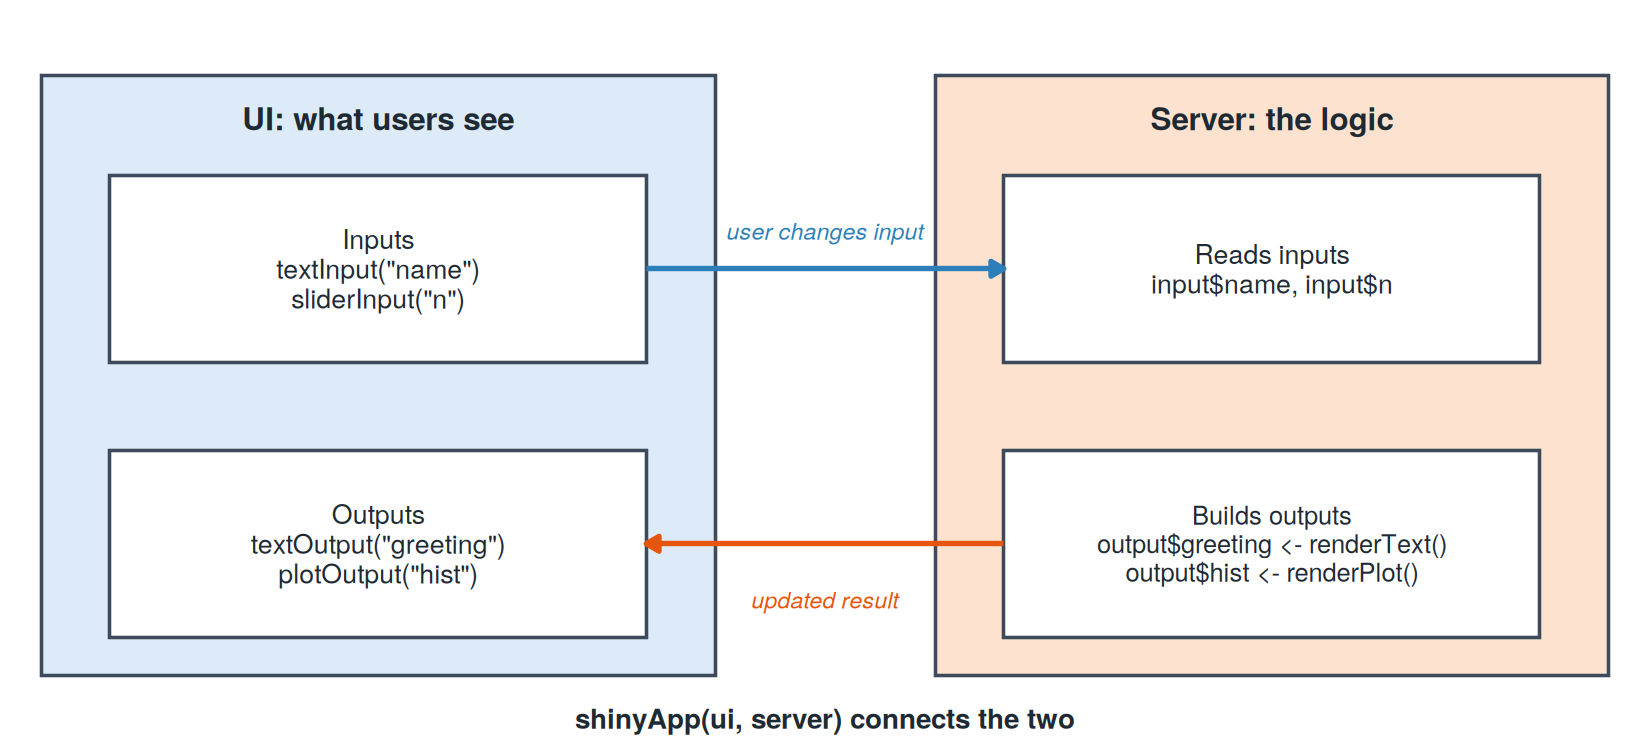

-   **UI** (user interface): layout, inputs, and empty placeholders for
    outputs
-   **Server**: a function that turns inputs into outputs
-   **`shinyApp(ui, server)`**: launches the app

## Your first app

Create a folder `01-hello-shiny/` with one file named exactly
**`app.R`**:

``` r
# ------------------------------------------------------------
# App 1: Hello, Shiny!
# The smallest useful Shiny app: two inputs, two outputs.
#
# Run it:
#   RStudio:       open this file and click "Run App"
#   R console:     shiny::runApp("01-hello-shiny")
#   Command line:  Rscript -e 'shiny::runApp("01-hello-shiny", launch.browser = TRUE)'
# ------------------------------------------------------------

library(shiny)

# ---- UI: what the user sees ---------------------------------
ui <- fluidPage(
  titlePanel("Hello, Shiny!"),

  sidebarLayout(
    sidebarPanel(
      textInput("name", "What is your name?", value = "student"),
      sliderInput("n", "Number of random points:",
                  min = 10, max = 1000, value = 100)
    ),

    mainPanel(
      textOutput("greeting"),
      plotOutput("hist")
    )
  )
)

# ---- Server: the logic behind the page ----------------------
server <- function(input, output, session) {

  # Re-runs whenever input$name changes
  output$greeting <- renderText({
    paste0("Hello, ", input$name, "! Here are ", input$n, " random numbers.")
  })

  # Re-runs whenever input$n changes
  output$hist <- renderPlot({
    hist(rnorm(input$n),
         col = "steelblue", border = "white",
         main = "Histogram of random values", xlab = "Value")
  })
}

# ---- Connect the two ----------------------------------------
shinyApp(ui = ui, server = server)
```

## What it looks like

<figure>
<img src="attachment:images/app1-hello-shiny.png"
alt="App 1: Hello, Shiny!" />
<figcaption aria-hidden="true">App 1: Hello, Shiny!</figcaption>
</figure>

-   Type a name: the greeting updates
-   Move the slider: the greeting **and** the histogram update
-   We never wrote “when the slider moves, redraw the plot”. Shiny
    figured it out.

## App file structure

**One-file app (recommended)**

    01-hello-shiny/
    └── app.R          # ui, server, and shinyApp() together

**Two-file app (older style, still common online)**

    my-app/
    ├── ui.R           # just the ui
    └── server.R       # just the server function

**Rules of thumb**

-   One app per folder
-   The file must be named `app.R` (or `ui.R` + `server.R`) for Run App
    to work
-   Data files the app needs go **inside** that folder

## Running an app: RStudio

1.  Open `app.R`
2.  Click **Run App** (green play button, top of the editor)
3.  Use the small dropdown next to it to choose where it opens:
    -   **Run in Window**: a separate RStudio window
    -   **Run in Viewer Pane**: inside RStudio
    -   **Run External**: your web browser

**Stop it:** click the red stop sign in the console, or press **Esc**

**Tip:** after editing `app.R`, just click **Reload App**. No need to
restart.

## Running an app: R console

The same thing, typed instead of clicked:

``` r
library(shiny)

# Run an app folder (path is relative to your working directory)
runApp("apps/01-hello-shiny")

# Open in your browser and pick a port
runApp("apps/01-hello-shiny", launch.browser = TRUE, port = 8080)
```

-   The console prints `Listening on http://127.0.0.1:8080`
-   That address is a **web server running on your own computer**
-   Paste it into any browser on this machine to view the app
-   Works the same in RStudio, VS Code, Positron, or plain R

## Running an app: command line

No editor needed. From a terminal (Git Bash on Windows, Terminal on
macOS):

``` bash
# go to the lecture folder first
cd shiny-lecture

# run and open the browser automatically
Rscript -e 'shiny::runApp("apps/01-hello-shiny", launch.browser = TRUE)'

# run on a fixed port, then visit http://127.0.0.1:8080
Rscript -e 'shiny::runApp("apps/01-hello-shiny", port = 8080)'
```

-   **Stop it:** `Ctrl + C` in the terminal
-   `Rscript` not found? R is not on your PATH. Use the full path to
    `Rscript`, or run from RStudio’s **Terminal** tab.
-   This is essentially how servers run Shiny apps for real users

## Running an app: summary

| Where | How | Stop |
|------------------------|------------------------|------------------------|
| RStudio | Open `app.R`, click **Run App** | Esc or stop sign |
| VS Code / Positron | Shiny extension, **Run Shiny App** button | Stop button |
| R console | `shiny::runApp("folder")` | Esc or Ctrl + C |
| Terminal | `Rscript -e 'shiny::runApp("folder")'` | Ctrl + C |

**Key idea:** every option starts the same thing, a small web server
powered by your R session. While it runs, that R session is busy serving
the app.

That is also why these notes show app code as text: running an app
inside a notebook would block the notebook.

## Inputs: widgets users interact with

| Function               | Widget                         | Value in `input$id` |
|------------------------|--------------------------------|---------------------|
| `sliderInput()`        | slider (single value or range) | number(s)           |
| `selectInput()`        | dropdown menu                  | text                |
| `textInput()`          | text box                       | text                |
| `numericInput()`       | number box                     | number              |
| `checkboxInput()`      | single checkbox                | `TRUE` / `FALSE`    |
| `checkboxGroupInput()` | several checkboxes             | vector of choices   |
| `radioButtons()`       | pick exactly one               | text                |
| `dateInput()`          | calendar                       | date                |
| `actionButton()`       | button                         | click count         |

Every input starts with the same two arguments:

``` r
sliderInput(inputId = "n", label = "Number of points:", ...)
```

## UI functions just write HTML

Run a UI function in the console and you get web page code back:

In [2]:
name_box <- textInput("name", "What is your name?")
cat(as.character(name_box))

ERROR: Error in textInput("name", "What is your name?"): could not find function "textInput"


-   Shiny writes the HTML for you
-   This is why you can build web apps without learning web development

## Outputs: placeholders plus render functions

Outputs always come in **pairs**: a placeholder in the UI and a render
function in the server.

| UI placeholder | Server render function | Shows |
|------------------------|------------------------|------------------------|
| `plotOutput("id")` | `renderPlot({ ... })` | plots (base R or ggplot2) |
| `tableOutput("id")` | `renderTable({ ... })` | data frames |
| `textOutput("id")` | `renderText({ ... })` | text |
| `verbatimTextOutput("id")` | `renderPrint({ ... })` | console-style output |
| `uiOutput("id")` | `renderUI({ ... })` | UI built on the fly |

``` r
# UI
plotOutput("hist")

# server
output$hist <- renderPlot({
  hist(rnorm(input$n))
})
```

## Connecting them: `input$` and `output$`

Inside the server:

-   **Read** inputs with `input$<id>`
-   **Write** outputs with `output$<id> <- render...()`
-   The **id strings must match exactly** between UI and server

``` r
ui <- fluidPage(
  sliderInput("n", ...),          # creates input$n
  plotOutput("hist")              # waits for output$hist
)

server <- function(input, output, session) {
  output$hist <- renderPlot({     # fills the "hist" placeholder
    hist(rnorm(input$n))          # reads the "n" slider
  })
}
```

## The most common beginner bugs

-   **Mismatched ids:** `plotOutput("histogram")` but `output$hist`.
    Nothing appears, and there is **no error**.
-   **Missing commas in the UI:** the UI is one big nested function
    call, so elements are separated by commas
-   **Forgetting the render function:** `output$hist <- hist(...)`
    fails; it must be `renderPlot({ hist(...) })`
-   **Reading inputs outside a reactive context:** `input$n` only works
    inside `render*()`, `reactive()`, or `observe*()`
-   **Wrong working directory:** `read.csv("data.csv")` fails because
    the file is not inside the app folder

**Debugging tip:** add `print(input$n)` inside a render function and
watch the console.

## Reactivity: the simple version

> When an input changes, anything that uses it updates automatically.

-   Like a spreadsheet: change a cell, and every formula that uses it
    recalculates
-   You describe **what** each output depends on, Shiny decides **when**
    to update it
-   Code does **not** run top to bottom once like a script

In App 1, Shiny tracks these dependencies:

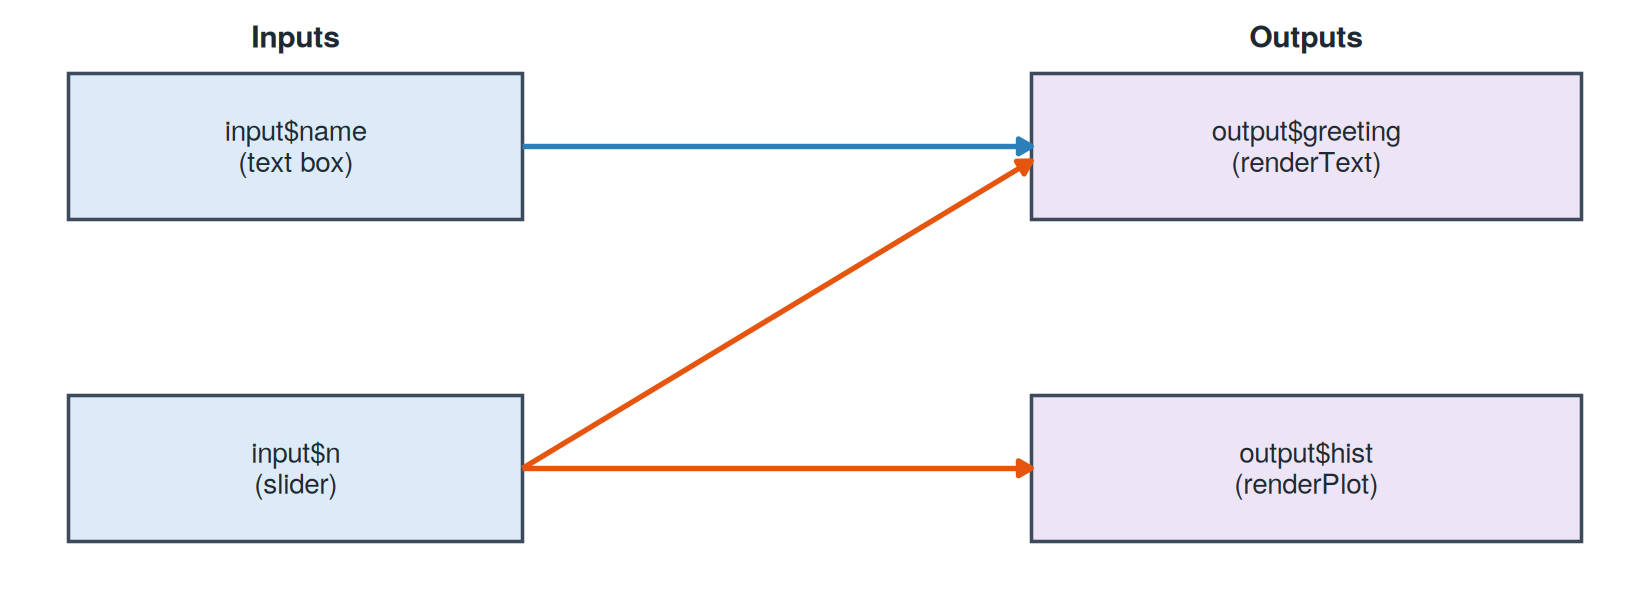

-   Change the name: only the greeting re-runs
-   Move the slider: the greeting **and** the histogram re-run

## Peek under the hood

Shiny’s reactive values can be explored right in the console:

In [6]:
reactiveConsole(TRUE)          # allow reactivity outside an app

price    <- reactiveVal(4)     # like an input
quantity <- reactiveVal(3)     # like an input
total    <- reactive(price() * quantity())

total()

12

In [7]:
quantity(10)                   # "move the slider"
total()                        # recalculates automatically

40

In [8]:
reactiveConsole(FALSE)

-   `total` remembers its recipe, not just its value
-   You will rarely write this in real apps; inputs play the role of
    `reactiveVal()`

## `reactive()`: compute once, use everywhere

Problem: several outputs need the same filtered data.

``` r
# Without reactive(): the filter runs 3 times
output$plot  <- renderPlot({ data <- filter(mpg, class == input$class); ... })
output$table <- renderTable({ data <- filter(mpg, class == input$class); ... })
output$count <- renderText({ data <- filter(mpg, class == input$class); ... })
```

``` r
# With reactive(): write it once, reuse it
filtered <- reactive({
  filter(mpg, class == input$class)
})

output$plot  <- renderPlot({ ggplot(filtered(), ...) })
output$table <- renderTable({ filtered() })
output$count <- renderText({ nrow(filtered()) })
```

-   Call it **with parentheses**: `filtered()`
-   Re-runs only when `input$class` changes, and caches the result
-   Less repeated code, faster apps

## Recall MPG data

| manufacturer | model      | displ | year | cyl | trans      | drv | cty | hwy | fl  | class   |
|-------|-------|-------|-------|-------|-------|-------|-------|-------|-------|-------|
| audi         | a4         | 1.8   | 1999 | 4   | auto(l5)   | f   | 18  | 29  | p   | compact |
| audi         | a4         | 1.8   | 1999 | 4   | manual(m5) | f   | 21  | 29  | p   | compact |
| audi         | a4         | 2.0   | 2008 | 4   | manual(m6) | f   | 20  | 31  | p   | compact |
| audi         | a4         | 2.0   | 2008 | 4   | auto(av)   | f   | 21  | 30  | p   | compact |
| audi         | a4         | 2.8   | 1999 | 6   | auto(l5)   | f   | 16  | 26  | p   | compact |
| audi         | a4         | 2.8   | 1999 | 6   | manual(m5) | f   | 18  | 26  | p   | compact |
| audi         | a4         | 3.1   | 2008 | 6   | auto(av)   | f   | 18  | 27  | p   | compact |
| audi         | a4 quattro | 1.8   | 1999 | 4   | manual(m5) | 4   | 18  | 26  | p   | compact |
| audi         | a4 quattro | 1.8   | 1999 | 4   | auto(l5)   | 4   | 16  | 25  | p   | compact |
| audi         | a4 quattro | 2.0   | 2008 | 4   | manual(m6) | 4   | 20  | 28  | p   | compact |

**Key:** `displ` engine size (L), `cyl` cylinders, `trans` transmission,
`drv` drive (f = front, r = rear, 4 = 4WD), `cty` / `hwy` city / highway
MPG, `fl` fuel type (p = premium)

## App 2: MPG Explorer

A regular (non-dashboard) app that uses more of Shiny’s toolbox.

<figure>
<img src="attachment:images/app2-mpg-explorer.png"
alt="App 2: MPG Explorer" />
<figcaption aria-hidden="true">App 2: MPG Explorer</figcaption>
</figure>

-   Multi-select, checkboxes, range slider, radio buttons, and dropdowns
-   Tabs for **Plot**, **Summary**, and **Data**
-   A **Reset** button and a **Download** button

# Walkthrough: App 2, MPG Explorer

Reading a real Shiny app from top to bottom

## The big picture

**What the app does:** lets users filter the `mpg` cars and explore them
as a plot, a summary, or a raw table.

**How the file is organized**

| Section | Lines | Job |
|------------------------|------------------------|------------------------|
| Setup | top | Load packages, prepare data and labels |
| UI | `ui <- fluidPage(...)` | Layout, inputs, output placeholders |
| Server | `server <- function(...)` | Filter data, build outputs, handle buttons |
| Launch | `shinyApp(ui, server)` | Start the app |

**Reading tip:** read the UI first to see *what users can do*, then the
server to see *what happens when they do it*.

## Step 1: setup

``` r
library(shiny)
library(ggplot2)
library(dplyr)

cars <- mpg

num_vars <- c(
  "Engine size (L)" = "displ",
  "City MPG"        = "cty",
  "Highway MPG"     = "hwy",
  "Cylinders"       = "cyl"
)
```

-   Code **outside** `ui` and `server` runs **once**, when the app
    starts
-   `num_vars` is a **named vector**:
    -   **names** (left) are what users see in the dropdown: “Highway
        MPG”
    -   **values** (right) are what the code receives: `"hwy"`

## Step 2: the page layout

``` r
ui <- fluidPage(
  titlePanel("MPG Explorer"),
  sidebarLayout(
    sidebarPanel( ...inputs... ),
    mainPanel( ...outputs... )
  )
)
```

    ┌──────────────────────────────────────────────┐
    │ MPG Explorer                    (titlePanel) │
    ├───────────────┬──────────────────────────────┤
    │ sidebarPanel  │ mainPanel                    │
    │               │                              │
    │ filters       │ "109 of 234 cars match..."   │
    │ plot settings │ [ Plot | Summary | Data ]    │
    │ buttons       │                              │
    └───────────────┴──────────────────────────────┘

-   `h4()` adds a small heading, `hr()` a divider line, `br()` a blank
    line

## Step 3: the filter inputs

``` r
selectInput("class", "Vehicle class:",
            choices = sort(unique(cars$class)),
            selected = sort(unique(cars$class)),
            multiple = TRUE)

checkboxGroupInput("year", "Model year:",
                   choices = c(1999, 2008), selected = c(1999, 2008))

sliderInput("displ", "Engine size (L):",
            min = min(cars$displ), max = max(cars$displ),
            value = range(cars$displ), step = 0.1)
```

| Input | Widget | What `input$...` holds |
|------------------------|------------------------|------------------------|
| `input$class` | multi-select dropdown | one or more classes, e.g. `c("suv", "compact")` |
| `input$year` | checkboxes | one or both years |
| `input$displ` | range slider (two handles) | two numbers: `c(low, high)` |

-   `choices` and `selected` come from the data, so nothing is typed by
    hand
-   Giving `value` **two** numbers turns a slider into a range slider

## Step 4: plot settings and buttons

``` r
selectInput("x", "X axis:", choices = num_vars, selected = "displ")
selectInput("y", "Y axis:", choices = num_vars, selected = "hwy")

radioButtons("color", "Color points by:",
             choices = c("Class" = "class", "Drive type" = "drv",
                         "Year" = "year", "None" = "none"))

actionButton("reset", "Reset filters", icon = icon("rotate-left"))
downloadButton("download", "Download data")
```

-   `input$x` and `input$y` hold **column names as text**, like `"hwy"`
-   `input$color` holds `"class"`, `"drv"`, `"year"`, or `"none"`
-   `input$reset` counts clicks: 0, 1, 2, …
-   The download button is special: it pairs with `output$download`

## Step 5: the output placeholders

``` r
mainPanel(
  textOutput("count"),
  tabsetPanel(
    tabPanel("Plot",    plotOutput("scatter", height = "450px")),
    tabPanel("Summary", tableOutput("summary")),
    tabPanel("Data",    tableOutput("table"))
  )
)
```

-   Four empty boxes, waiting for the server to fill them
-   `tabsetPanel()` stacks the three views behind clickable tabs
-   Each id must match the server: `"scatter"` here, `output$scatter`
    there

## Step 6: the shared filtered data

``` r
filtered <- reactive({
  cars |>
    filter(class %in% input$class,
           year  %in% input$year,
           displ >= input$displ[1],
           displ <= input$displ[2])
})
```

-   Keeps only the cars that pass **all four** conditions
-   `%in%` keeps a row if its value matches **any** of the selected
    choices
-   `input$displ[1]` is the slider’s low end and `input$displ[2]` its
    high end
-   **Every output uses `filtered()`**, so the filtering is written once
    and runs once per change

## Step 7: the count and the plot

``` r
output$count <- renderText({
  paste(nrow(filtered()), "of", nrow(cars), "cars match your filters.")
})
```

``` r
output$scatter <- renderPlot({
  validate(need(nrow(filtered()) > 0, "No cars match these filters."))

  p <- ggplot(filtered(), aes(x = .data[[input$x]], y = .data[[input$y]]))
  ...
})
```

-   `validate(need(...))`: if no cars are left, show a friendly message
    instead of an error
-   `.data[[input$x]]`: `input$x` is text like `"hwy"`, and this tells
    ggplot “use the column with this name”
-   Then an `if` / `else` adds colored points, or plain blue points when
    “None” is picked
-   `names(num_vars)[num_vars == input$x]` looks up the friendly axis
    label: `"hwy"` becomes “Highway MPG”

## Step 8: the summary and data tabs

``` r
output$summary <- renderTable({
  filtered() |>
    group_by(class) |>
    summarise(cars = n(),
              avg_city_mpg = mean(cty),
              avg_hwy_mpg  = mean(hwy)) |>
    arrange(desc(avg_hwy_mpg))
}, digits = 1)

output$table <- renderTable({
  filtered() |>
    select(manufacturer, model, year, class, displ, cyl, drv, cty, hwy)
})
```

-   Ordinary dplyr code, the same as you would write in a script
-   The only Shiny parts: `renderTable({ })` around it, and `filtered()`
    instead of `mpg`

## Step 9: the reset button

``` r
observeEvent(input$reset, {
  updateSelectInput(session, "class", selected = sort(unique(cars$class)))
  updateCheckboxGroupInput(session, "year", selected = c(1999, 2008))
  updateSliderInput(session, "displ", value = range(cars$displ))
})
```

-   `observeEvent(input$reset, { ... })` means “every time the button is
    clicked, run this”
-   It **does something** (moves the inputs back) instead of **making an
    output**
-   `update*Input()` changes a widget from the server, and `session`
    says which user’s page to change
-   Moving the inputs triggers `filtered()`, so every output updates on
    its own

## Step 10: the download button

``` r
output$download <- downloadHandler(
  filename = function() "mpg-filtered.csv",
  content  = function(file) write.csv(filtered(), file, row.names = FALSE)
)
```

-   `filename`: what the downloaded file is called
-   `content`: how to write it, which here means saving the current
    `filtered()` data as a CSV
-   Users download exactly what they filtered, nothing more

## Recap: follow one click

**The user unchecks 1999:**

1.  `input$year` changes from `c(1999, 2008)` to `2008`
2.  `filtered()` re-runs: now only 2008 cars
3.  Everything that uses `filtered()` updates: the **count**, **plot**,
    **summary**, and **table**

**The user changes the X axis:**

1.  `input$x` changes
2.  Only the **plot** re-runs, because it is the only thing that uses
    `input$x`
3.  `filtered()` does **not** re-run, since no filter changed

> Shiny only redoes the work that depends on what changed.

## App 2: how the pieces connect

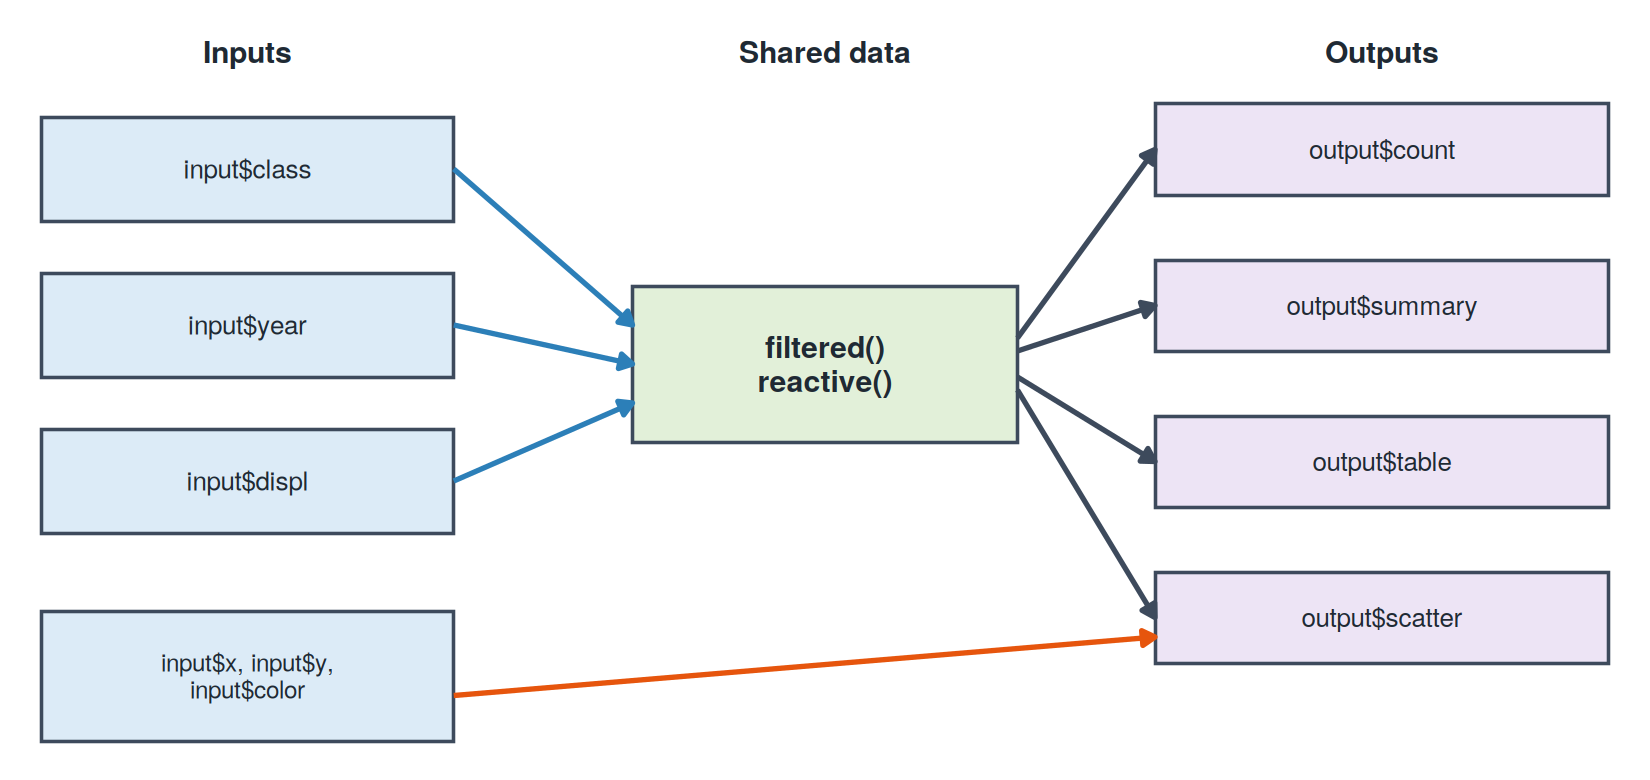

-   Filter inputs feed **one** `reactive()`, which feeds every output
-   Plot settings (orange) go straight to the plot, so changing the axis
    does **not** re-filter the data

## App 2: new tools it introduces

**Respond to a button with `observeEvent()`** (for side effects, not
outputs)

``` r
observeEvent(input$reset, {
  updateSliderInput(session, "displ", value = range(cars$displ))
})
```

**Show a friendly message instead of an error with `validate()`**

``` r
validate(need(nrow(filtered()) > 0, "No cars match these filters."))
```

**Let users download the data with `downloadHandler()`**

``` r
output$download <- downloadHandler(
  filename = function() "mpg-filtered.csv",
  content  = function(file) write.csv(filtered(), file, row.names = FALSE)
)
```

**Organize views with `tabsetPanel()`**

``` r
tabsetPanel(
  tabPanel("Plot",    plotOutput("scatter")),
  tabPanel("Summary", tableOutput("summary"))
)
```

## App 2: full code

``` r
# ------------------------------------------------------------
# App 2: MPG Explorer
# A classic Shiny app (not a dashboard) that shows off more widgets
# and the key reactivity tools:
#   - several input types (select, checkbox group, slider, radio)
#   - reactive() to share one filtered dataset across outputs
#   - tabsetPanel() for multiple views
#   - observeEvent() + update*Input() for a "Reset" button
#   - downloadHandler() to export the filtered data
#
# Run it:  shiny::runApp("02-mpg-explorer")
# ------------------------------------------------------------

library(shiny)
library(ggplot2)
library(dplyr)

# mpg ships with ggplot2: 234 cars from 1999 and 2008
cars <- mpg

# Friendly labels for the numeric variables users can plot
num_vars <- c(
  "Engine size (L)" = "displ",
  "City MPG"        = "cty",
  "Highway MPG"     = "hwy",
  "Cylinders"       = "cyl"
)

# ---- UI ------------------------------------------------------
ui <- fluidPage(
  titlePanel("MPG Explorer"),

  sidebarLayout(
    sidebarPanel(
      h4("Filter the cars"),

      selectInput("class", "Vehicle class:",
                  choices  = sort(unique(cars$class)),
                  selected = sort(unique(cars$class)),
                  multiple = TRUE),

      checkboxGroupInput("year", "Model year:",
                         choices  = c(1999, 2008),
                         selected = c(1999, 2008),
                         inline   = TRUE),

      sliderInput("displ", "Engine size (L):",
                  min = min(cars$displ), max = max(cars$displ),
                  value = range(cars$displ), step = 0.1),

      hr(),
      h4("Plot settings"),

      selectInput("x", "X axis:", choices = num_vars, selected = "displ"),
      selectInput("y", "Y axis:", choices = num_vars, selected = "hwy"),

      radioButtons("color", "Color points by:",
                   choices = c("Class" = "class", "Drive type" = "drv",
                               "Year" = "year", "None" = "none"),
                   selected = "class"),

      hr(),
      actionButton("reset", "Reset filters", icon = icon("rotate-left")),
      downloadButton("download", "Download data")
    ),

    mainPanel(
      textOutput("count"),
      br(),
      tabsetPanel(
        tabPanel("Plot",    plotOutput("scatter", height = "450px")),
        tabPanel("Summary", tableOutput("summary")),
        tabPanel("Data",    tableOutput("table"))
      )
    )
  )
)

# ---- Server --------------------------------------------------
server <- function(input, output, session) {

  # One reactive expression feeds every output below.
  # It re-runs only when one of the filter inputs changes.
  filtered <- reactive({
    cars |>
      filter(class %in% input$class,
             year  %in% input$year,
             displ >= input$displ[1],
             displ <= input$displ[2])
  })

  output$count <- renderText({
    paste(nrow(filtered()), "of", nrow(cars), "cars match your filters.")
  })

  output$scatter <- renderPlot({
    # validate() shows a friendly message instead of an error
    validate(need(nrow(filtered()) > 0, "No cars match these filters."))

    p <- ggplot(filtered(), aes(x = .data[[input$x]], y = .data[[input$y]]))

    if (input$color == "none") {
      p <- p + geom_point(size = 3, alpha = 0.7, color = "steelblue")
    } else {
      color_labels <- c(class = "Class", drv = "Drive type", year = "Year")
      p <- p +
        geom_point(aes(color = factor(.data[[input$color]])),
                   size = 3, alpha = 0.7) +
        labs(color = color_labels[[input$color]])
    }

    p +
      labs(x = names(num_vars)[num_vars == input$x],
           y = names(num_vars)[num_vars == input$y]) +
      theme_minimal(base_size = 15)
  })

  output$summary <- renderTable({
    filtered() |>
      group_by(class) |>
      summarise(cars         = n(),
                avg_city_mpg = mean(cty),
                avg_hwy_mpg  = mean(hwy)) |>
      arrange(desc(avg_hwy_mpg))
  }, digits = 1)

  output$table <- renderTable({
    filtered() |>
      select(manufacturer, model, year, class, displ, cyl, drv, cty, hwy)
  })

  # observeEvent() runs code for its side effect (here: changing inputs)
  observeEvent(input$reset, {
    updateSelectInput(session, "class", selected = sort(unique(cars$class)))
    updateCheckboxGroupInput(session, "year", selected = c(1999, 2008))
    updateSliderInput(session, "displ", value = range(cars$displ))
  })

  output$download <- downloadHandler(
    filename = function() "mpg-filtered.csv",
    content  = function(file) write.csv(filtered(), file, row.names = FALSE)
  )
}

shinyApp(ui, server)
```

## Workflow tip: prototype outside Shiny first

Get the plot working as plain R, **then** swap in the inputs:

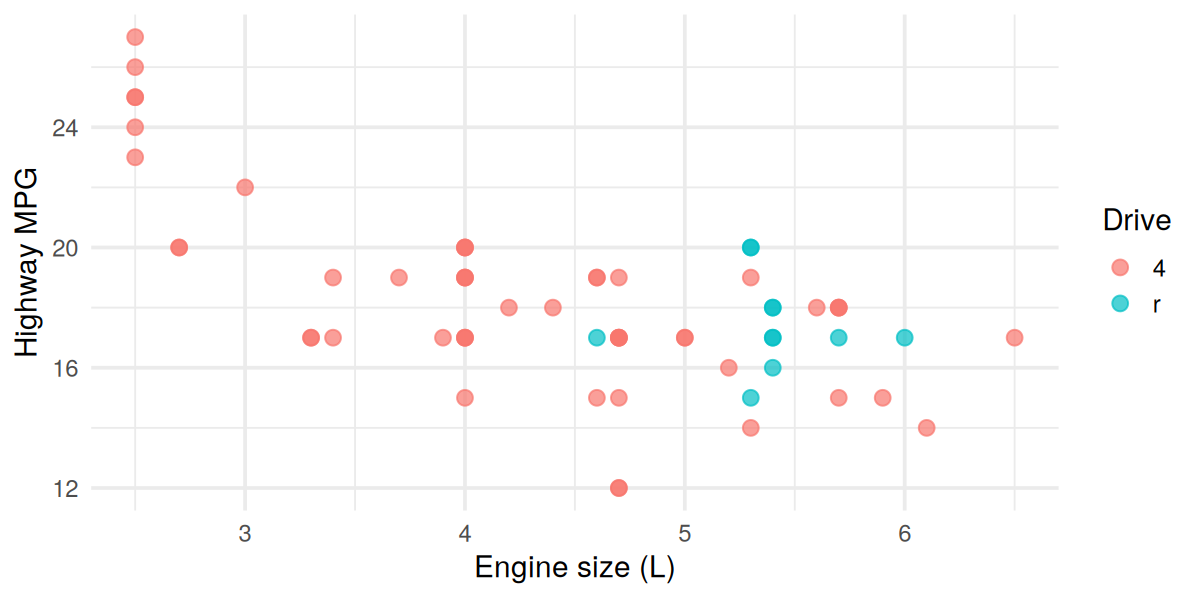

In [11]:
chosen_class <- "suv"                          # later: input$class

mpg |>
  filter(class == chosen_class) |>
  ggplot(aes(displ, hwy, color = drv)) +
  geom_point(size = 3, alpha = 0.7) +
  labs(x = "Engine size (L)", y = "Highway MPG", color = "Drive") +
  theme_minimal(base_size = 14)

-   Debugging is much easier in a script than inside a running app
-   Once it works, move it into `renderPlot({ ... })` and replace
    `chosen_class` with `input$class`

# What Is a Dashboard?

The ideas behind dashboards, and when they need a server

## Definition

> A **dashboard** is a single screen showing the most important
> information about something, at a glance.

-   Named after a car dashboard: speed, fuel, warnings, all visible
    without digging
-   **Purpose:** monitoring and quick decisions
-   **Not for:** deep, step-by-step analysis or long explanations

**Everyday examples**

-   Fitness app: steps, heart rate, sleep this week
-   Weather app: temperature now, forecast, alerts
-   Course LMS: grades, upcoming deadlines, announcements

## Core building blocks

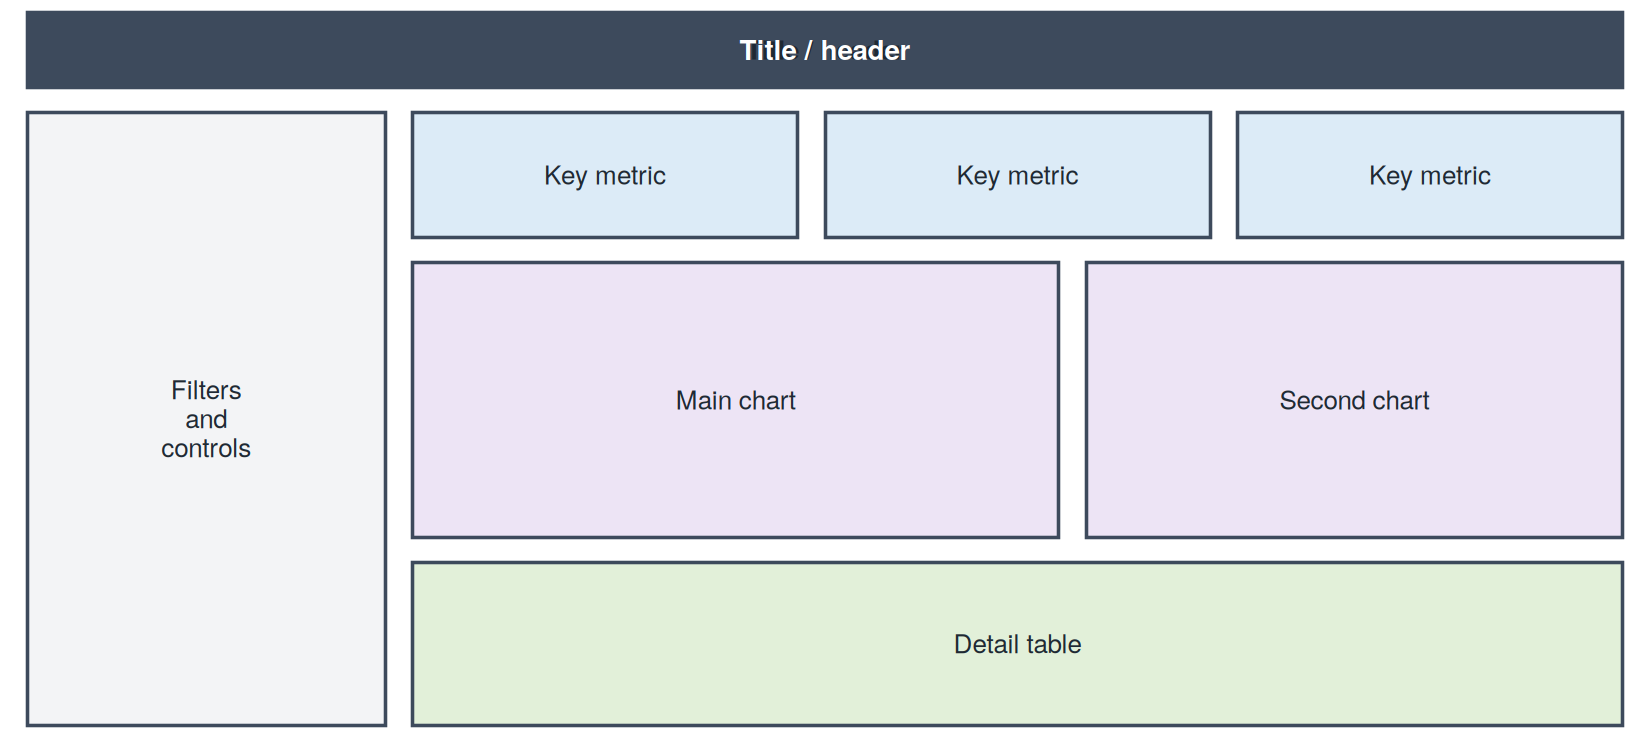

-   **Key metrics:** headline numbers (total sales, average score,
    number of cases)
-   **Visualizations:** a few focused charts showing trends or
    comparisons
-   **Filters and controls:** let users focus on what matters to them
-   **Layout:** controls in a sidebar, content arranged by importance

## Design principles

-   **Know your audience:** what questions do they need answered?
-   **Most important first:** people read top-left to bottom-right, so
    headline numbers go at the top
-   **Less is more:** every element must earn its place
-   **Be consistent:** same colors, units, and number formats everywhere
-   **Label clearly:** plain-language titles (“Bigger engines, lower
    mileage”) beat variable names (`displ vs hwy`)
-   **Make it honest:** start bar charts at zero, show units, cite the
    data source

## Dashboard vs. report

**Report**

-   Tells one story, once
-   Usually static (PDF, web page, slides)
-   The author decides what you see
-   Written for reading start to finish
-   Example: a Quarto website or research paper

**Dashboard**

-   Answers many questions, repeatedly
-   Interactive and often regularly updated
-   The user decides what to look at
-   Built for scanning and exploring
-   Example: a live sales or public health tracker

## Why does a dashboard need a server?

You can already make interactive charts without Shiny (for example with
**Plotly** or **htmlwidgets**). So why run R behind the page?

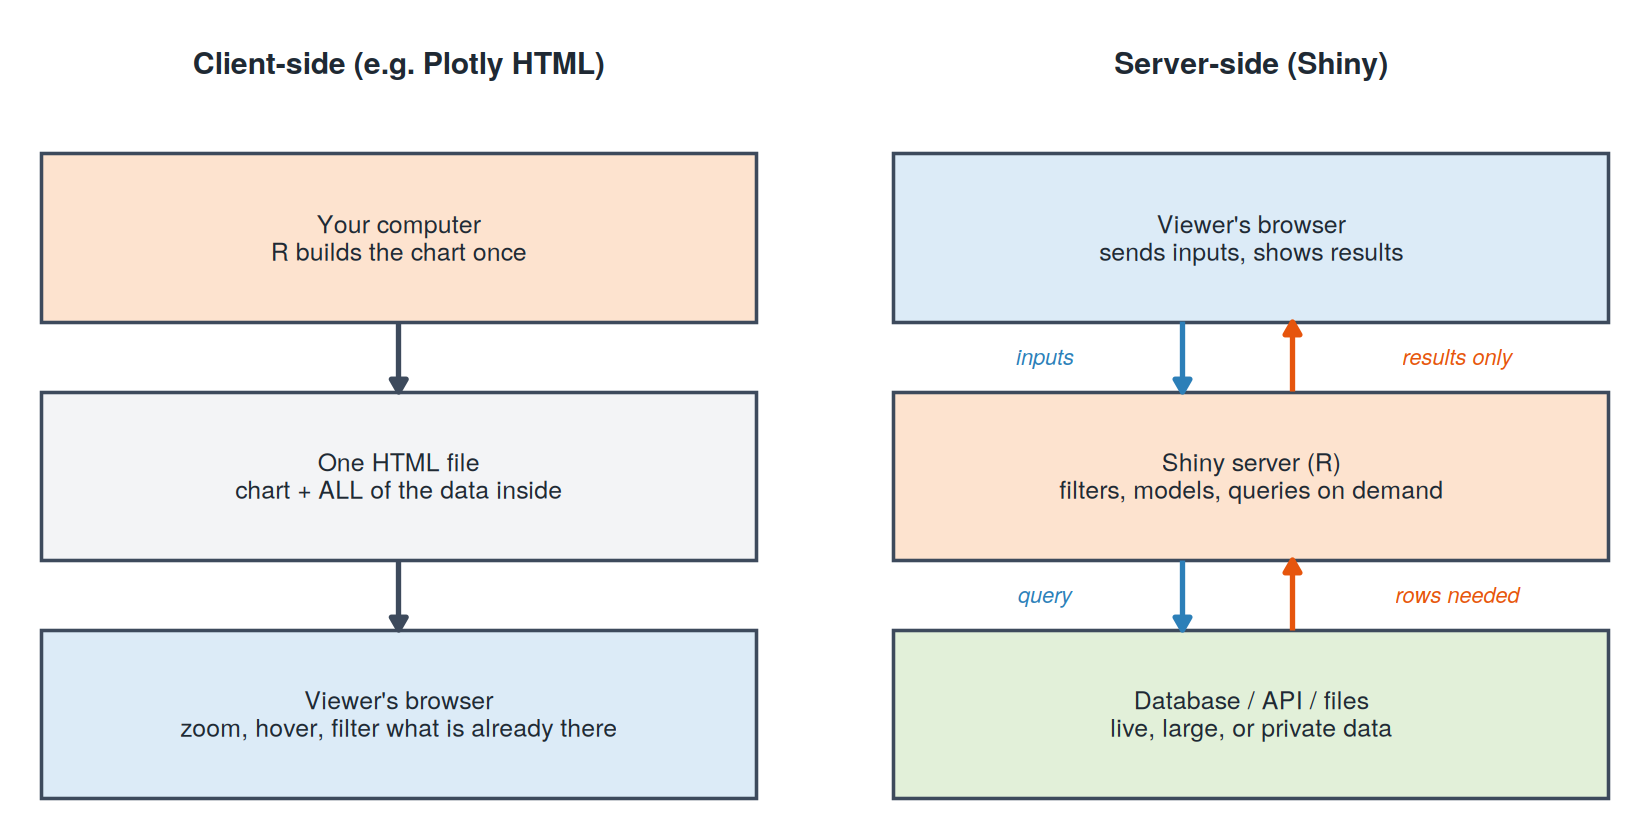

-   **Client-side:** interactivity with the data you already shipped
-   **Server-side:** interactivity that can **do new work** every time a
    user clicks

## Reasons to use a server

**Data**

-   **Live data:** connect to a database or API that updates constantly;
    users always see the latest numbers
-   **Big data:** the server summarizes millions of rows and sends back
    only the result; an HTML chart would have to embed every row

**Computation**

-   **Real analysis on demand:** fit a model, run a simulation, or make
    a forecast from the user’s inputs
-   **Generated outputs:** build a custom PDF report or a filtered CSV
    download

**Security**

-   **Privacy:** raw data never leaves the server; users only see
    summaries
-   **Logins:** different users can see different data
-   **Secrets:** passwords and API keys stay on the server, never in the
    page

**Two-way apps**

-   **Uploads:** users analyze their own files
-   **Writing back:** forms, surveys, and annotations saved to a
    database

## The trade-off

**Client-side (Plotly, htmlwidgets)**

-   Free and easy to host (any static site, like a Quarto website)
-   Works offline once loaded
-   Limited to the data in the page
-   Anyone can download that data

**Server-side (Shiny)**

-   Can do anything R can do
-   Data can be big, live, and private
-   Needs a **running R server** somewhere
-   Hosting takes setup, and may cost money at scale

**Rule of thumb:** if a static chart answers the question, use a static
chart. Reach for Shiny when users need the app to **compute** something
new.

# Dashboards with bslib

Same Shiny engine, a modern dashboard body

## What is bslib?

-   An R package from Posit for **layouts and themes** in Shiny and R
    Markdown / Quarto
-   Built on **Bootstrap 5**, the most popular web styling toolkit
-   Actively maintained; the recommended way to build Shiny dashboards
    today

**What changes, what stays the same**

-   **Same:** inputs, outputs, `render*()` functions, `reactive()`, the
    whole server
-   **Different:** only the UI functions that arrange things on the page

> Shiny is the engine. bslib is the car body around it.

**Note:** you will see **shinydashboard** in older tutorials. Same idea,
older package, different function names (`dashboardPage()`, `box()`,
`valueBox()`).

## Key functions

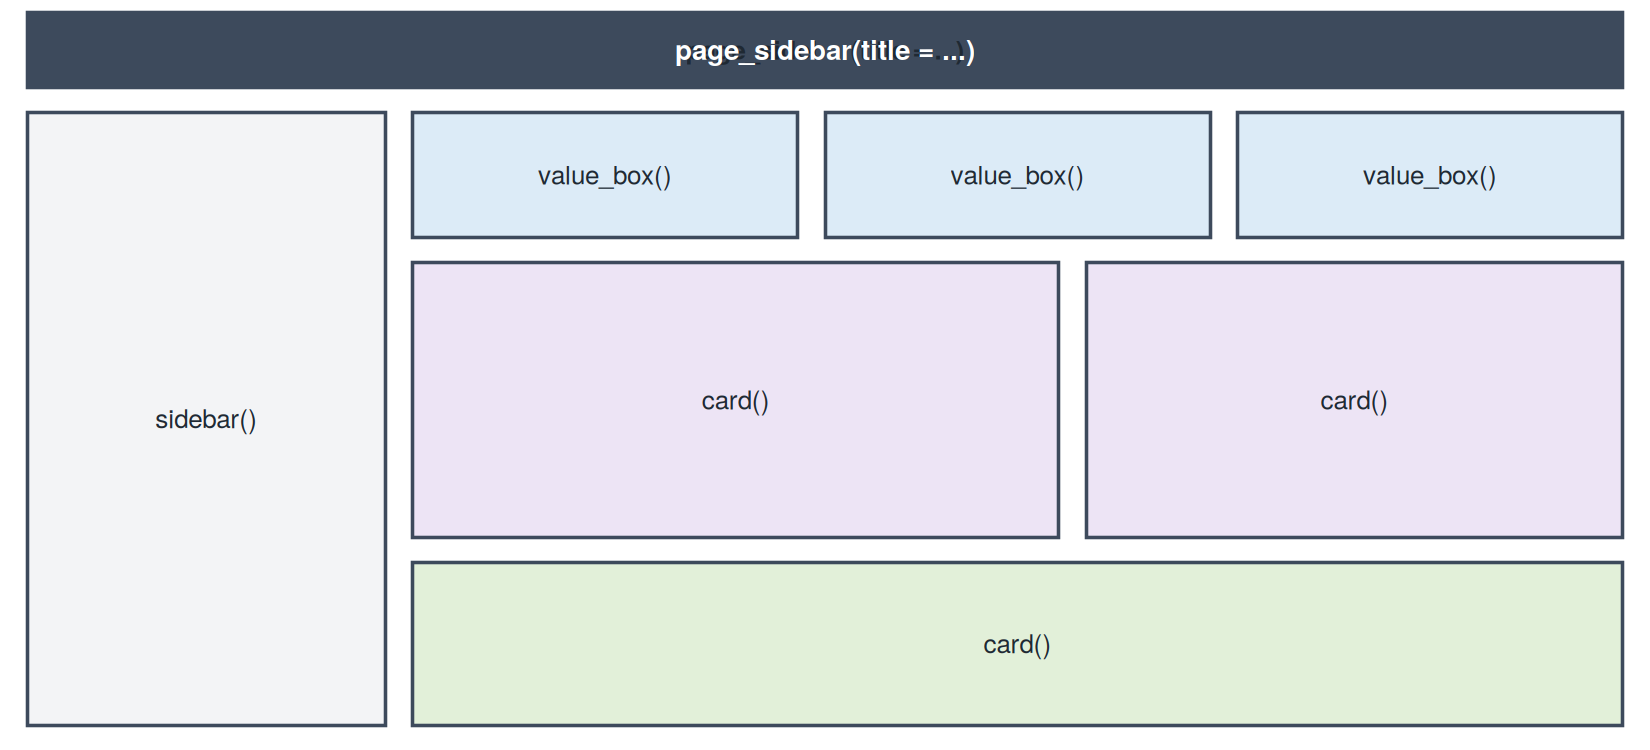

| Function                   | Role                                          |
|----------------------------|-----------------------------------------------|
| `page_sidebar()`           | The whole page: title bar, sidebar, main area |
| `sidebar()`                | Collapsible panel for inputs                  |
| `value_box()`              | Headline number with an optional icon         |
| `card()` + `card_header()` | A bordered panel for a chart or table         |
| `layout_columns()`         | Places items side by side in a row            |
| `bs_theme()`               | Colors, fonts, and ready-made themes          |

## Classic Shiny vs. bslib

**Classic Shiny (App 1)**

``` r
ui <- fluidPage(
  titlePanel("My app"),
  sidebarLayout(
    sidebarPanel(
      sliderInput("n", ...)
    ),
    mainPanel(
      plotOutput("plot")
    )
  )
)
```

**bslib dashboard**

``` r
ui <- page_sidebar(
  title = "My app",
  sidebar = sidebar(
    sliderInput("n", ...)
  ),
  card(
    card_header("My plot"),
    plotOutput("plot")
  )
)
```

-   Same inputs and outputs, less nesting
-   The **server function does not change at all**

## The data: a toy coffee shop

App 3 uses **made-up data**, created right inside `app.R`:

``` r
set.seed(42)
coffee <- data.frame(
  day      = 1:60,
  visitors = round(120 + 2 * (1:60) + rnorm(60, sd = 15))
)
```

**What the code does**

-   `day`: days 1 through 60 (about two months)
-   `visitors`: starts around 120, **grows by about 2 visitors per
    day**, plus random day-to-day noise
-   `rnorm(60, sd = 15)`: adds realistic ups and downs
-   `set.seed(42)`: makes the “random” numbers the same every time, so
    everyone sees identical results

**First few rows**

| day | visitors |
|-----|----------|
| 1   | 143      |
| 2   | 116      |
| 3   | 131      |
| 4   | 137      |
| 5   | 136      |

**Quick summary (all 60 days)**

| Statistic                | Value     |
|--------------------------|-----------|
| Fewest visitors in a day | 116       |
| Most visitors in a day   | 250       |
| Average per day          | about 181 |
| Total visitors           | 10,836    |

**In the dashboard**

-   The slider picks how many of the **most recent** days to show (7 to
    60)
-   The value boxes show the **total** and **average** for those days
-   Default (last 30 days): **6,276** total visitors, **209** per day

## App 3: Hello, bslib!

The smallest possible dashboard: toy data, one slider, two value boxes,
one chart.

``` r
# ------------------------------------------------------------
# App 3: Hello, bslib!
# The smallest possible dashboard: a sidebar, two value boxes,
# and one chart card. Uses made-up (toy) data.
#
# Same Shiny engine as App 1. Only the UI functions change:
#   fluidPage()  ->  page_sidebar()
#   panels       ->  card() and value_box()
#
# Run it:  shiny::runApp("03-hello-bslib")
# ------------------------------------------------------------

library(shiny)
library(bslib)

# Toy data: daily visitors to a coffee shop for 60 days
set.seed(42)
coffee <- data.frame(
  day      = 1:60,
  visitors = round(120 + 2 * (1:60) + rnorm(60, sd = 15))
)

# ---- UI ------------------------------------------------------
ui <- page_sidebar(
  title = "Coffee Shop Dashboard",

  sidebar = sidebar(
    sliderInput("days", "Show the last N days:",
                min = 7, max = 60, value = 30)
  ),

  # Two headline numbers side by side
  layout_columns(
    value_box(
      title = "Total visitors",
      value = textOutput("total"),
      showcase = icon("users"),
      theme = "primary"
    ),
    value_box(
      title = "Average per day",
      value = textOutput("average"),
      showcase = icon("mug-hot"),
      theme = "secondary"
    )
  ),

  # One chart in a card
  card(
    card_header("Daily visitors"),
    plotOutput("trend")
  )
)

# ---- Server --------------------------------------------------
server <- function(input, output, session) {

  recent <- reactive({
    tail(coffee, input$days)
  })

  output$total   <- renderText(format(sum(recent()$visitors), big.mark = ","))
  output$average <- renderText(round(mean(recent()$visitors)))

  output$trend <- renderPlot({
    plot(recent()$day, recent()$visitors, type = "b", pch = 19,
         col = "steelblue", xlab = "Day", ylab = "Visitors")
  })
}

shinyApp(ui, server)
```

## What it looks like

<figure>
<img src="attachment:images/app3-hello-bslib.png"
alt="App 3: Hello, bslib!" />
<figcaption aria-hidden="true">App 3: Hello, bslib!</figcaption>
</figure>

-   The sidebar collapses with the arrow at the top
-   The layout resizes automatically on a phone or a small window

## Value boxes

``` r
value_box(
  title    = "Total visitors",       # small label
  value    = textOutput("total"),    # the big number (can be reactive)
  showcase = icon("users"),          # optional icon on the left
  theme    = "primary"               # color: primary, success, info, ...
)
```

-   `value` can be fixed text or a `textOutput()` that the server fills
    in
-   `icon()` uses the free **Font Awesome** icon set; search names at
    fontawesome.com
-   Put several in `layout_columns()` to make a row

## Cards and layout

``` r
layout_columns(
  col_widths = c(7, 5),          # widths out of 12
  card(
    full_screen = TRUE,          # adds an "expand" button
    card_header("Main chart"),
    plotOutput("scatter")
  ),
  card(
    card_header("Second chart"),
    plotOutput("bars")
  )
)
```

-   The page is a **12-column grid**: `c(7, 5)` means 7/12 and 5/12 of
    the width
-   `full_screen = TRUE` lets users enlarge a card, which is great for
    presentations
-   Items in `page_sidebar()` stack vertically; `layout_columns()` puts
    them side by side

## Themes

Change the whole look with one argument:

``` r
ui <- page_sidebar(
  title = "My dashboard",
  theme = bs_theme(bootswatch = "flatly", primary = "#2C7FB8"),
  ...
)
```

-   `bootswatch` offers ready-made themes: `"flatly"`, `"minty"`,
    `"darkly"`, `"lux"`, `"sandstone"`, …
-   Set your own colors and fonts:
    `bs_theme(primary = ..., base_font = ...)`
-   **Try themes live:** add `bs_themer()` as the first line of your
    server function, then pick from a menu while the app runs
-   Bootstrap themes are the same system Quarto websites use, so your
    app can match your site

# Demo: Fuel Economy Dashboard

Everything combined into one polished app

## The data: `mpg`

Ships with ggplot2, so there is nothing to download.

In [15]:
head(mpg)

-   **234 cars**, model years **1999** and **2008**
-   Categories to filter by: `manufacturer`, `class`, `drv` (drive
    type), `year`, `cyl`
-   Numbers to summarize: `cty` and `hwy` (city and highway miles per
    gallon), `displ` (engine size)

## Plan before you build

**Audience:** someone shopping for a fuel-efficient car

**Questions the dashboard should answer**

1.  How many cars match what I am looking for?
2.  What mileage can I expect in the city and on the highway?
3.  Do bigger engines really mean worse mileage?
4.  Which brands are the most efficient?
5.  Which specific models should I look at?

**Map questions to building blocks**

| Question                | Building block                                 |
|-------------------------|------------------------------------------------|
| 1, 2                    | Three value boxes                              |
| 3                       | Scatter plot card                              |
| 4                       | Bar chart card                                 |
| 5                       | Top 10 table card                              |
| “what I am looking for” | Sidebar filters: class, year, drive, cylinders |

## The final product

<figure>
<img src="attachment:images/app4-mpg-dashboard.png"
alt="App 4: Fuel Economy Dashboard" />
<figcaption aria-hidden="true">App 4: Fuel Economy
Dashboard</figcaption>
</figure>

## Step 1: prepare the data

Clean labels once, at the top of `app.R`, outside the server:

In [16]:
cars <- mpg |>
  mutate(
    drive = recode(drv, "f" = "Front", "r" = "Rear", "4" = "4WD"),
    make  = tools::toTitleCase(manufacturer)
  )

cars |> count(drive)

-   Code **outside** the server runs once when the app starts
-   Code **inside** the server runs for each user and re-runs when
    inputs change

## Step 2: the layout (UI)

The skeleton, with details removed:

``` r
ui <- page_sidebar(
  title = "Fuel Economy Dashboard",
  theme = bs_theme(bootswatch = "flatly", primary = "#2C7FB8"),

  sidebar = sidebar(
    selectInput("class", "Vehicle class", ...),
    checkboxGroupInput("year", "Model year", ...),
    checkboxGroupInput("drive", "Drive type", ...),
    sliderInput("cyl", "Cylinders", ...)
  ),

  layout_columns(                                       # row 1
    value_box("Cars selected",       textOutput("n_cars"),  ...),
    value_box("Average highway MPG", textOutput("avg_hwy"), ...),
    value_box("Average city MPG",    textOutput("avg_cty"), ...)
  ),

  layout_columns(col_widths = c(7, 5),                  # row 2
    card(card_header("Bigger engines, lower mileage"), plotOutput("scatter")),
    card(card_header("Highway MPG by manufacturer"),   plotOutput("by_make"))
  ),

  card(card_header("Top 10 most fuel-efficient models"),  # row 3
       tableOutput("top10"))
)
```

## Step 3: one shared reactive dataset

``` r
filtered <- reactive({
  data <- cars |>
    filter(year  %in% input$year,
           drive %in% input$drive,
           cyl   >= input$cyl[1],
           cyl   <= input$cyl[2])

  if (input$class != "All classes") {
    data <- filter(data, class == input$class)
  }
  data
})
```

-   Every value box, chart, and table uses `filtered()`
-   Change one filter: the data is filtered **once**, then all 6 outputs
    update
-   `input$cyl` is a range slider, so it has two values: `[1]` and `[2]`

## Step 4: fill in the outputs

``` r
# Value boxes: just a number
output$n_cars  <- renderText(nrow(filtered()))
output$avg_hwy <- renderText(round(mean(filtered()$hwy), 1))

# Charts: normal ggplot code using filtered()
output$scatter <- renderPlot({
  ggplot(filtered(), aes(displ, hwy, color = drive)) +
    geom_jitter(size = 3, alpha = 0.7) +
    labs(x = "Engine size (liters)", y = "Highway MPG")
})

# Table: normal dplyr code using filtered()
output$top10 <- renderTable({
  filtered() |>
    arrange(desc(hwy)) |>
    slice_head(n = 10)
})
```

**Pattern:** every output is ordinary R code wrapped in a `render*()`
function, using `filtered()` instead of the raw data.

## Live demo: things to try

-   Pick **suv**: value boxes drop, the scatter shows the trade-off
    clearly
-   Uncheck **4WD**: which brands disappear from the bar chart?
-   Set cylinders to **4 only**: what is the best highway MPG?
-   Choose **2seater** and **Front** only: the friendly “no cars match”
    message
-   Click the **expand** icon on a chart card to go full screen
-   Collapse the sidebar with the arrow

**Ask while demoing:** which input triggered which output? Why did the
table change but not the page layout?

## App 4: full code

``` r
# ------------------------------------------------------------
# App 4: Fuel Economy Dashboard (final product)
# A polished but beginner-friendly bslib dashboard built on the
# mpg dataset from ggplot2.
#
# Structure:
#   sidebar      -> filters (inputs)
#   value boxes  -> headline numbers
#   cards        -> two charts and a table
#   reactive()   -> one filtered dataset shared by every output
#
# Run it:  shiny::runApp("04-mpg-dashboard")
# ------------------------------------------------------------

library(shiny)
library(bslib)
library(ggplot2)
library(dplyr)

# ---- Data ----------------------------------------------------
cars <- mpg |>
  mutate(
    drive = recode(drv, "f" = "Front", "r" = "Rear", "4" = "4WD"),
    make  = tools::toTitleCase(manufacturer)
  )

all_classes <- sort(unique(cars$class))

# ---- Theme ---------------------------------------------------
my_theme <- bs_theme(
  version   = 5,
  bootswatch = "flatly",
  primary   = "#2C7FB8"
)

# Shared ggplot style so every chart looks consistent
theme_dash <- theme_minimal(base_size = 14) +
  theme(panel.grid.minor = element_blank(),
        legend.position  = "bottom")

# ---- UI ------------------------------------------------------
ui <- page_sidebar(
  title = "Fuel Economy Dashboard",
  theme = my_theme,

  sidebar = sidebar(
    width = 280,

    selectInput("class", "Vehicle class",
                choices  = c("All classes", all_classes),
                selected = "All classes"),

    checkboxGroupInput("year", "Model year",
                       choices  = c(1999, 2008),
                       selected = c(1999, 2008),
                       inline   = TRUE),

    checkboxGroupInput("drive", "Drive type",
                       choices  = c("Front", "Rear", "4WD"),
                       selected = c("Front", "Rear", "4WD")),

    sliderInput("cyl", "Cylinders",
                min = 4, max = 8, value = c(4, 8), step = 1),

    hr(),
    p(class = "text-muted small",
      "Data: ggplot2::mpg, EPA fuel economy for 38 popular models, 1999 and 2008.")
  ),

  # Row 1: headline numbers
  layout_columns(
    fill = FALSE,
    value_box(
      title = "Cars selected",
      value = textOutput("n_cars"),
      showcase = icon("car"),
      theme = "primary"
    ),
    value_box(
      title = "Average highway MPG",
      value = textOutput("avg_hwy"),
      showcase = icon("road"),
      theme = "success"
    ),
    value_box(
      title = "Average city MPG",
      value = textOutput("avg_cty"),
      showcase = icon("city"),
      theme = "info"
    )
  ),

  # Row 2: two charts side by side
  layout_columns(
    col_widths = c(7, 5),
    card(
      full_screen = TRUE,
      card_header("Bigger engines, lower mileage"),
      plotOutput("scatter")
    ),
    card(
      full_screen = TRUE,
      card_header("Highway MPG by manufacturer"),
      plotOutput("by_make")
    )
  ),

  # Row 3: table of the most efficient cars
  card(
    card_header("Top 10 most fuel-efficient models (highway)"),
    tableOutput("top10")
  )
)

# ---- Server --------------------------------------------------
server <- function(input, output, session) {

  # One filtered dataset, reused by every output
  filtered <- reactive({
    data <- cars |>
      filter(year  %in% input$year,
             drive %in% input$drive,
             cyl   >= input$cyl[1],
             cyl   <= input$cyl[2])

    if (input$class != "All classes") {
      data <- filter(data, class == input$class)
    }
    data
  })

  # Friendly message when the filters remove every car
  check_data <- function() {
    validate(need(nrow(filtered()) > 0,
                  "No cars match these filters. Try widening them."))
  }

  # ---- Value boxes ----
  output$n_cars  <- renderText(nrow(filtered()))
  output$avg_hwy <- renderText({
    check_data()
    round(mean(filtered()$hwy), 1)
  })
  output$avg_cty <- renderText({
    check_data()
    round(mean(filtered()$cty), 1)
  })

  # ---- Charts ----
  output$scatter <- renderPlot({
    check_data()
    ggplot(filtered(), aes(displ, hwy, color = drive)) +
      geom_jitter(size = 3, alpha = 0.7, width = 0.05, height = 0.3) +
      scale_color_manual(values = c(Front = "#2C7FB8", Rear = "#E6550D",
                                    `4WD` = "#31A354")) +
      labs(x = "Engine size (liters)", y = "Highway MPG", color = "Drive") +
      theme_dash
  })

  output$by_make <- renderPlot({
    check_data()
    filtered() |>
      group_by(make) |>
      summarise(hwy = mean(hwy)) |>
      ggplot(aes(x = hwy, y = reorder(make, hwy))) +
      geom_col(fill = "#2C7FB8") +
      geom_text(aes(label = round(hwy, 1)), hjust = -0.2, size = 4) +
      scale_x_continuous(expand = expansion(mult = c(0, 0.15))) +
      labs(x = "Average highway MPG", y = NULL) +
      theme_dash
  })

  # ---- Table ----
  output$top10 <- renderTable({
    check_data()
    filtered() |>
      arrange(desc(hwy), desc(cty)) |>
      distinct(make, model, year, .keep_all = TRUE) |>
      slice_head(n = 10) |>
      transmute(Make = make, Model = model, Year = as.integer(year),
                Class = class, Drive = drive,
                `City MPG` = as.integer(cty), `Highway MPG` = as.integer(hwy))
  }, striped = TRUE, hover = TRUE, width = "100%")
}

shinyApp(ui, server)
```

## Sharing your app: why deployment?

-   So far the app only runs **on your computer**, while R is running
-   Close RStudio and the app is gone
-   To share a link, the app must run on a **server**: a computer that
    is always on, with R installed

> Deploying = moving the app from your laptop to a server so anyone can
> open a link.

**Options**

| Service | What it is | Best for |
|------------------------|------------------------|------------------------|
| **shinyapps.io** | Posit’s hosting service, free tier available | Class projects, portfolios |
| **Posit Connect** | Hosting a company installs on its own servers | Workplaces |
| **Shinylive** | Runs the app entirely in the browser, no R server | Simple apps on static sites |

## Deploying to shinyapps.io

**One-time setup**

1.  Create a free account at **shinyapps.io**
2.  Install the deployment package: `install.packages("rsconnect")`
3.  In shinyapps.io go to **Account \> Tokens**, click **Show**, and
    copy the command:

``` r
rsconnect::setAccountInfo(name   = "your-account",
                          token  = "XXXXXXXX",
                          secret = "XXXXXXXX")
```

**Every deploy**

-   RStudio: click the blue **Publish** button next to Run App, or
-   Console:

``` r
rsconnect::deployApp("apps/04-mpg-dashboard")
```

-   A few minutes later you get a link like
    `https://your-account.shinyapps.io/04-mpg-dashboard/`
-   The free tier limits the number of apps and active hours per month

## Deployment gotchas

-   **Use relative paths:** `read.csv("data/cars.csv")`, never
    `read.csv("C:/Users/me/Desktop/cars.csv")`
-   **Keep data inside the app folder:** the server only receives what
    is in that folder
-   **Load every package with `library()` at the top:** this is how the
    server knows what to install
-   **No `install.packages()` in `app.R`**
-   **Never put passwords in your code:** use environment variables for
    API keys and database logins
-   **Test locally first:** if it does not run on your machine, it will
    not run on the server
-   **Read the logs:** a gray “Disconnected from the server” screen
    means an R error; the logs on shinyapps.io tell you which one

## Bonus: Shinylive (no server needed)

Shinylive runs R **inside the browser** using WebAssembly.

``` r
install.packages("shinylive")

# convert an app folder into a static website folder
shinylive::export("apps/03-hello-bslib", "site")

# preview it locally
httpuv::runStaticServer("site")
```

-   The `site/` folder can be hosted anywhere static files go (GitHub
    Pages, a Quarto website)
-   A Quarto extension (`quarto-ext/shinylive`) can embed apps directly
    in a Quarto page

**But remember Part 2:** everything runs on the viewer’s machine, so

-   All data is downloaded to the browser (nothing private)
-   No live database connections or server secrets
-   First load is slower, and not every R package is supported

# Wrap-up

## Key takeaways

-   A Shiny app = **UI** + **server** + `shinyApp(ui, server)`
-   Inputs are read with `input$id`; outputs are written with
    `output$id <- render*()`
-   **Reactivity:** when an input changes, everything that uses it
    updates automatically
-   `reactive()` computes shared results once and reuses them
-   A **dashboard** shows the most important information at a glance
-   Use a **server** when the app must compute, protect, or fetch
    something new
-   **bslib** turns a Shiny app into a modern dashboard by changing only
    the UI
-   Deploy to **shinyapps.io** so others can use your app with just a
    link

## Practice and resources

**Practice with the lecture apps**

1.  App 1: add a `selectInput()` that changes the histogram color
2.  App 3: add a third value box showing the busiest day
3.  App 4: add a `selectInput()` for manufacturer, or a card with a
    boxplot of `hwy` by `class`
4.  Deploy App 3 or App 4 to shinyapps.io and share the link

**Resources**

-   Shiny docs and gallery: [shiny.posit.co](https://shiny.posit.co)
-   bslib docs:
    [rstudio.github.io/bslib](https://rstudio.github.io/bslib)
-   *Mastering Shiny* by Hadley Wickham (free online):
    [mastering-shiny.org](https://mastering-shiny.org)
-   Font Awesome icons:
    [fontawesome.com/icons](https://fontawesome.com/icons)